# Figure 3. ROI-averaged BMI–RNI spline curves

Set phenotype below to `bmip` or `perc_median` and re-run for each.



In [1]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt


os.environ["BMI_PHENO_VARIABLE"] = "perc_median"  # "bmip" or "perc_median"
os.environ["BMI_IMAGING_CEPH_ROOT"] = "/space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis"
os.environ["BMI_IMAGING_ANALYSIS_DIR"] = "perc_median"  # "bmip" or "perc_median"
os.environ["BMI_IMAGING_RESULTS_RUN"] = "results_2026_06_29"
PHENO = os.environ.get("BMI_PHENO_VARIABLE", "bmip").strip()

PHENO_PROFILES = {
    "bmip": {
        "design_tag": "Sbmi",
        "xname": "bmi",
        "pheno_xlabel": "BMI percentile",
        "x_plot_min": 0,
        "x_plot_max": 100,
    },
    "perc_median": {
        "design_tag": "Sperc",
        "xname": "perc_median",
        "pheno_xlabel": "Percent from median",
        "x_plot_min": -30,
        "x_plot_max": 140,
    },
}

if PHENO not in PHENO_PROFILES:
    raise ValueError(
        f"BMI_PHENO_VARIABLE must be one of {list(PHENO_PROFILES)}; got {PHENO!r}"
    )

prof = PHENO_PROFILES[PHENO]
design_tag = prof["design_tag"]
xname = prof["xname"]
pheno_xlabel = prof["pheno_xlabel"]

CEPH_ROOT = os.environ.get(
    "BMI_IMAGING_CEPH_ROOT",
    "/space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis",
)
ANALYSIS_DIR = os.environ.get("BMI_IMAGING_ANALYSIS_DIR", PHENO)
RESULTS_RUN = os.environ.get("BMI_IMAGING_RESULTS_RUN", "results_2026_06_29")

results_dir = os.path.join(CEPH_ROOT, ANALYSIS_DIR, "results", RESULTS_RUN)
base_directory = os.path.join(results_dir, "roi_data_for_plots")
plots_base_directory = os.path.join(results_dir, "plots")

effect_types = ["splines"]
xnames = [xname]
modality = "rni"
correction_type = "fdr"  # 'bonferroni', 'fdr', or 'all_voxels'

# x-axis limits (profile defaults; override with BMI_IMAGING_PLOT_XMIN / XMAX)
x_plot_min = int(os.environ.get("BMI_IMAGING_PLOT_XMIN", str(prof["x_plot_min"])))
x_plot_max = int(os.environ.get("BMI_IMAGING_PLOT_XMAX", str(prof["x_plot_max"])))


def _find_designmat_dir(sex_suffix):
    pattern = os.path.join(base_directory, f"designmat*{design_tag}*_{sex_suffix}")
    matches = sorted(glob.glob(pattern))
    if not matches:
        raise FileNotFoundError(
            f"No ROI folder matching {pattern}. Check s9 output and BMI_IMAGING_RESULTS_RUN."
        )
    return matches[0]


sex_dirs = {
    "female": _find_designmat_dir("females"),
    "male": _find_designmat_dir("males"),
}

print(f"Pheno: {PHENO} | xname: {xname}")
print(f"Results: {results_dir}")
print(f"Female ROI dir: {sex_dirs['female']}")
print(f"Male ROI dir:   {sex_dirs['male']}")
print(f"Plot x range: [{x_plot_min}, {x_plot_max}]")

colors = {"female": "#D10467", "male": "#0011A3"}
ci_colors = {"female": "#F5ABCF", "male": "#B7BEF7"}

def load_data(directory, effect_type, xname, laterality_type='lateralized', correction_type='fdr'):
    """
    Load data from the new hierarchical directory structure.
    
    Parameters:
    -----------
    directory : str
        Base directory containing the design matrix results
    effect_type : str
        Type of effect (e.g., 'splines')
    xname : str
        Variable name (e.g., pheno xname from s9)
    laterality_type : str
        Type of laterality: 'lateralized', 'bilateral', or 'non_lateralized'
    correction_type : str
        Multiple comparison correction: 'bonferroni', 'fdr', or 'all_voxels'
    
    Returns:
    --------
    dict : Dictionary mapping ROI names to DataFrames
    """
    # Navigate to betas/laterality_type/correction_type subdirectory
    correction_dir = os.path.join(directory, 'betas', laterality_type, correction_type)
    if not os.path.exists(correction_dir):
        print(f"Warning: Directory not found: {correction_dir}")
        return {}
    
    pattern = f"{modality}_{effect_type}_{xname}_CI_"
    files = [f for f in os.listdir(correction_dir) if f.startswith(pattern) and f.endswith('.txt')]
    
    print(f"\n{laterality_type} - Looking in: {correction_dir}")
    print(f"Pattern: {pattern}")
    print(f"Found {len(files)} files: {files}")
    
    data = {}
    for file in files:
        file_path = os.path.join(correction_dir, file)
        # Extract ROI name (everything after 'CI_' and before '.txt')
        roi_name = file.replace(pattern, '').replace('.txt', '')
        try:
            df = pd.read_csv(file_path)
            data[roi_name] = df
        except Exception as e:
            print(f"Error loading {file_path}: {e}")
    
    print(f"Loaded {len(data)} ROIs: {list(data.keys())}")
    return data


Pheno: perc_median | xname: perc_median
Results: /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/perc_median/results/results_2026_06_29
Female ROI dir: /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/perc_median/results/results_2026_06_29/roi_data_for_plots/designmat1f_SpercSageSpdsIncEducPCsScanSoft_nodemean_females
Male ROI dir:   /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/perc_median/results/results_2026_06_29/roi_data_for_plots/designmat1m_SpercSageSpdsIncEducPCsScanSoft_nodemean_males
Plot x range: [-30, 140]


## Figure 3



bilateral - Looking in: /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/perc_median/results/results_2026_06_29/roi_data_for_plots/designmat1f_SpercSageSpdsIncEducPCsScanSoft_nodemean_females/betas/bilateral/fdr
Pattern: rni_splines_perc_median_CI_
Found 33 files: ['rni_splines_perc_median_CI_Bilateral-ILF.txt', 'rni_splines_perc_median_CI_Bilateral-pSCS.txt', 'rni_splines_perc_median_CI_Bilateral-Putamen.txt', 'rni_splines_perc_median_CI_Bilateral-IFSFC.txt', 'rni_splines_perc_median_CI_Bilateral-Caudate.txt', 'rni_splines_perc_median_CI_Bilateral-pSLF.txt', 'rni_splines_perc_median_CI_Bilateral-Central_Lateral-Lateral_Posterior-Medial_Pulvinar.txt', 'rni_splines_perc_median_CI_Bilateral-CgC.txt', 'rni_splines_perc_median_CI_Bilateral-Anterior.txt', 'rni_splines_perc_median_CI_Bilateral-Unc.txt', 'rni_splines_perc_median_CI_Bilateral-Cerebral-Cortex.txt', 'rni_splines_perc_median_CI_Bilateral-CgH.txt', 'rni_splines_perc_median_CI_Bilateral-SCS.txt', 'rni_splines_perc_median_

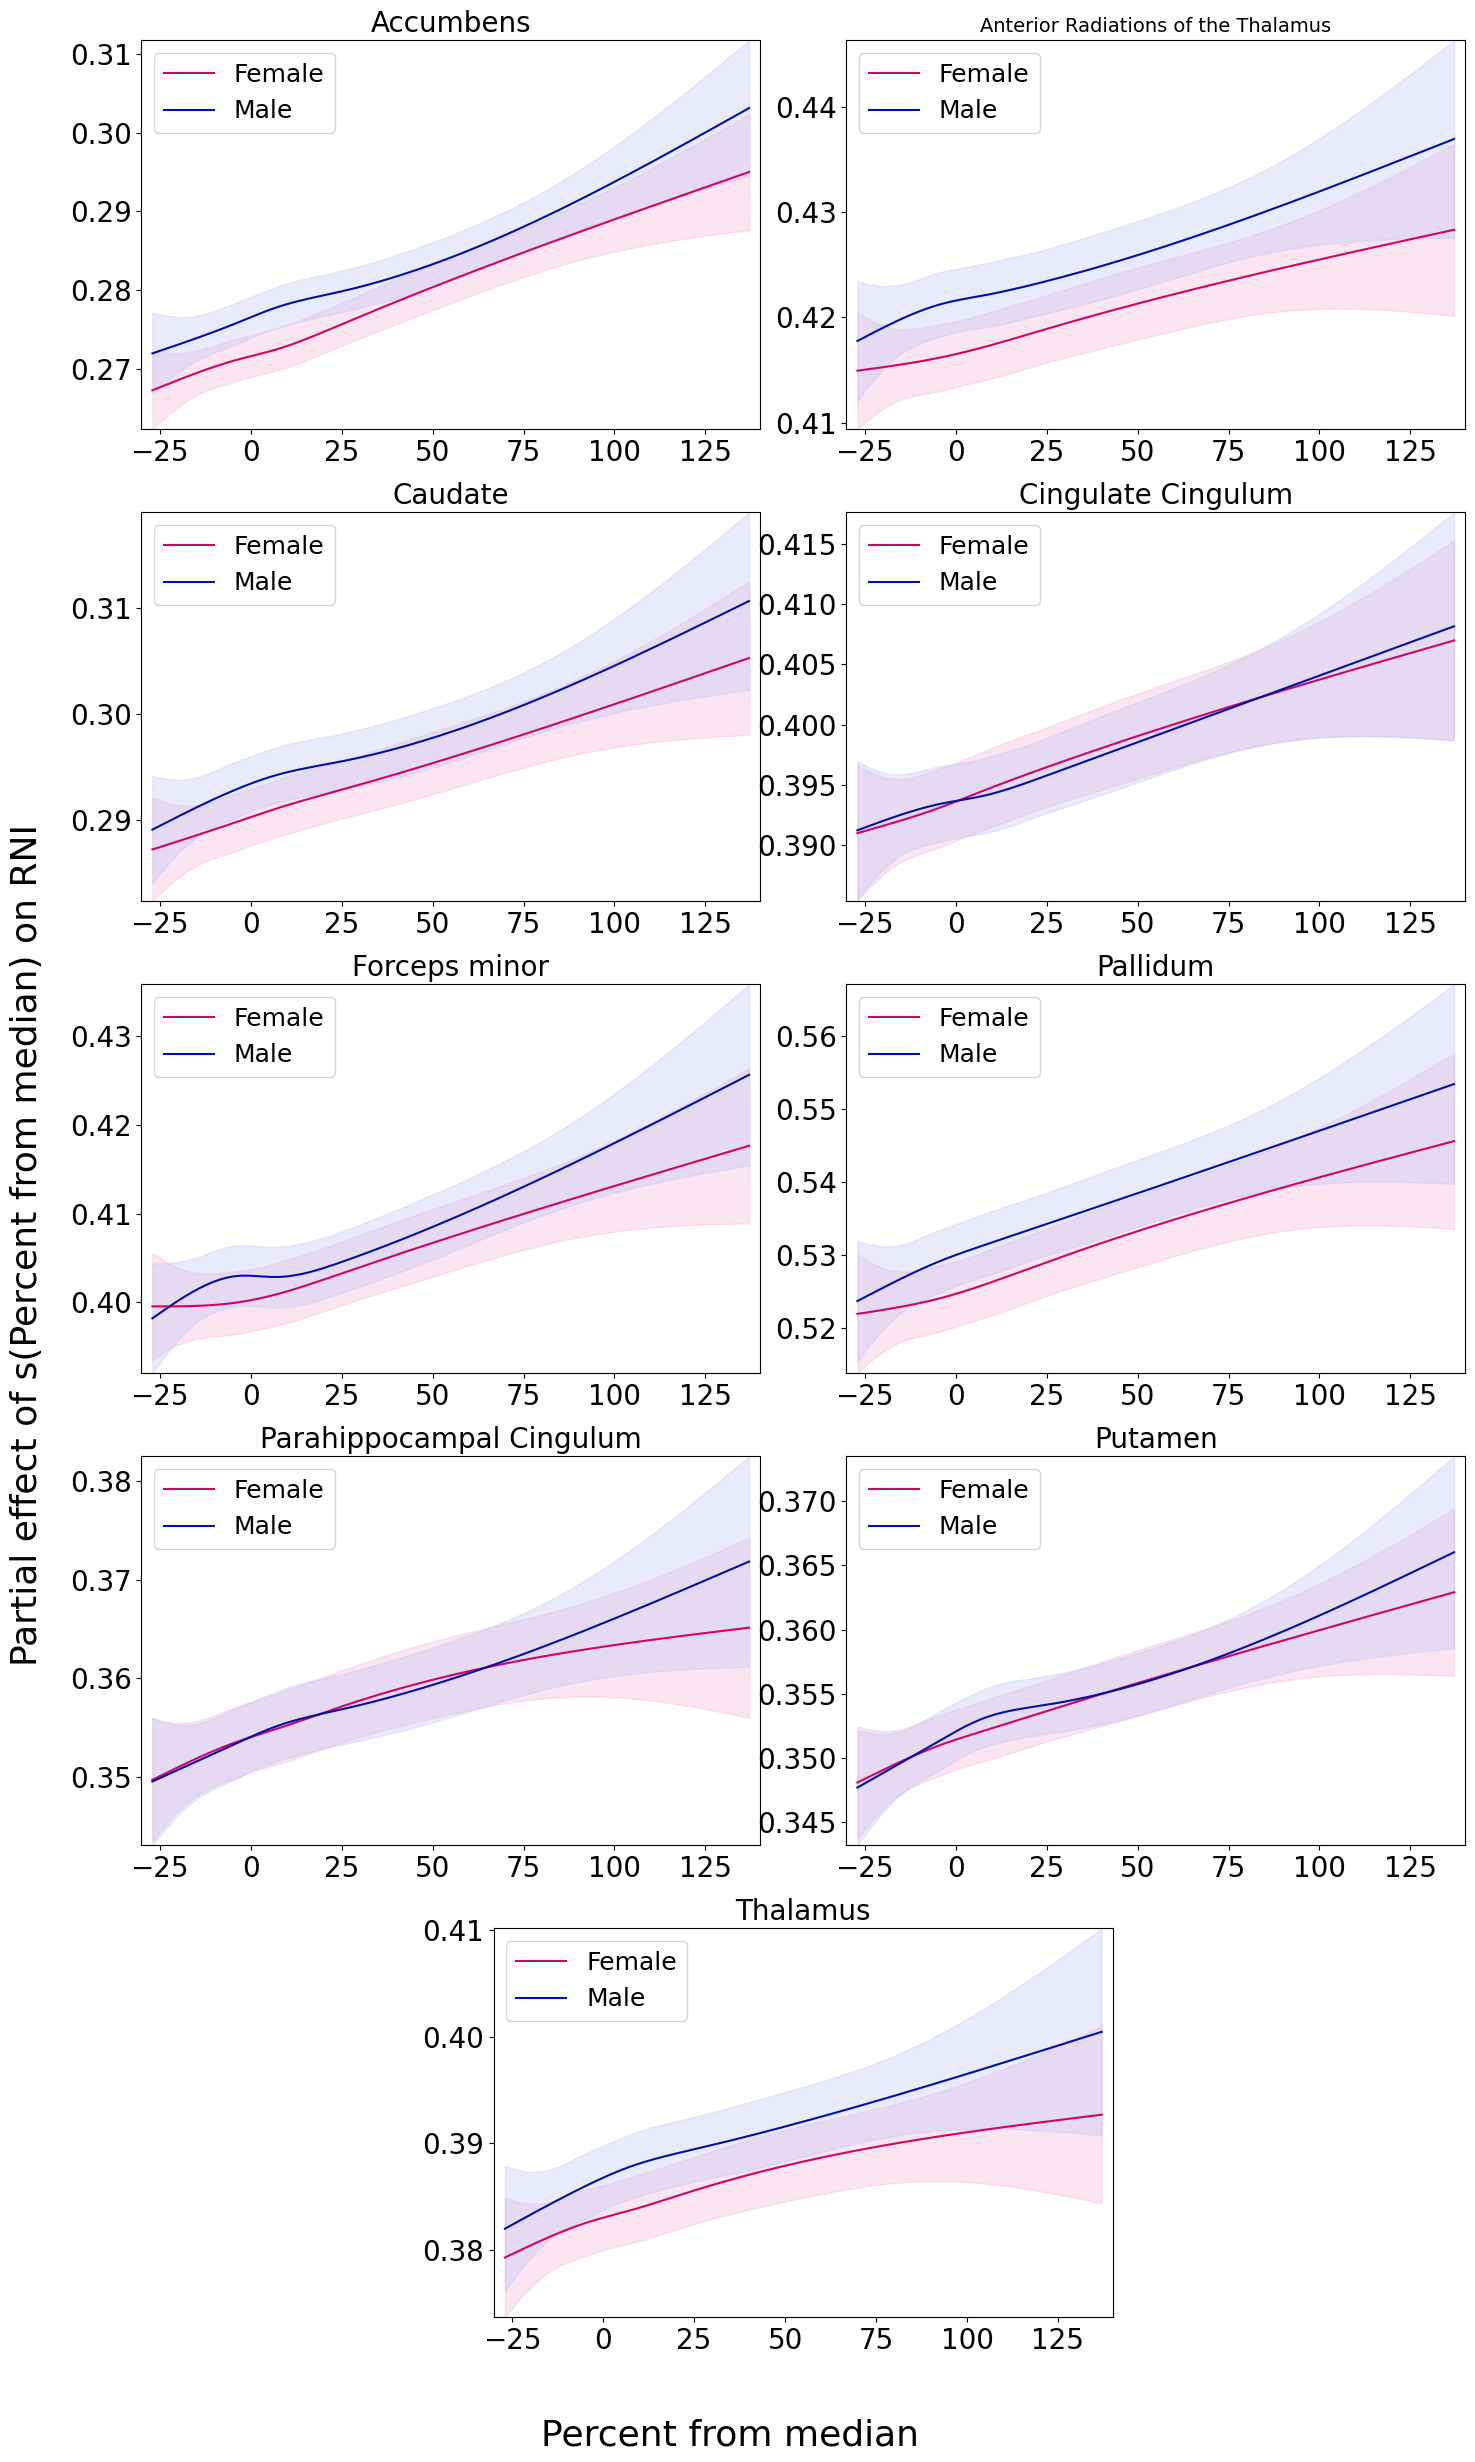

In [2]:
# Combined PNG: selected bilateral + non-lateralized ROIs (2 columns, last centered)


import matplotlib.gridspec as gridspec


def _make_combined_roi_axes(fig, n_rois=9):
    """Two columns; last ROI centered on the bottom row when n_rois is odd."""
    n_rows = (n_rois + 1) // 2
    gs = gridspec.GridSpec(n_rows, 4, figure=fig)
    axes = []
    for idx in range(n_rois):
        if idx < n_rois - 1:
            row, side = divmod(idx, 2)
            col_start = 0 if side == 0 else 2
            axes.append(fig.add_subplot(gs[row, col_start:col_start + 2]))
        else:
            axes.append(fig.add_subplot(gs[n_rows - 1, 1:3]))
    return axes

def plot_combined_selected_rois(xname, effect_type, save_png=False, save_pdf=False, save_svg=False):
    """
    Create a single combined figure with selected bilateral and non-lateralized ROIs
    in two columns (last ROI centered on the bottom row), alphabetically by display name.
    """
    # Load bilateral data
    bilateral_female = load_data(sex_dirs['female'], effect_type, xname, 
                                 laterality_type='bilateral', correction_type=correction_type)
    bilateral_male = load_data(sex_dirs['male'], effect_type, xname, 
                               laterality_type='bilateral', correction_type=correction_type)
    
    # Load non-lateralized data
    nonlat_female = load_data(sex_dirs['female'], effect_type, xname, 
                              laterality_type='non_lateralized', correction_type=correction_type)
    nonlat_male = load_data(sex_dirs['male'], effect_type, xname, 
                            laterality_type='non_lateralized', correction_type=correction_type)
    
    # Define the ROIs we want and their display names
    # Key: (data_key, source) → display_name
    selected_rois = sorted([
        ('Bilateral-Accumbens-area', 'bilateral', 'Accumbens'),
        ('Bilateral-ATR', 'bilateral', 'Anterior Radiations of the Thalamus'),
        ('Bilateral-Caudate', 'bilateral', 'Caudate'),
        ('Bilateral-CgC', 'bilateral', 'Cingulate Cingulum'),
        ('Fmin', 'non_lateralized', 'Forceps minor'),
        ('Bilateral-Pallidum', 'bilateral', 'Pallidum'),
        ('Bilateral-CgH', 'bilateral', 'Parahippocampal Cingulum'),
        ('Bilateral-Putamen', 'bilateral', 'Putamen'),
        ('Bilateral-Thalamus-Proper', 'bilateral', 'Thalamus'),
    ], key=lambda item: item[2])
    
    x_min, x_max = x_plot_min, x_plot_max
    
    fig = plt.figure(figsize=(15, 25))
    axes = _make_combined_roi_axes(fig, n_rois=len(selected_rois))
    
    for idx, (roi_key, source, disp_name) in enumerate(selected_rois):
        ax = axes[idx]
        
        # Select the right data source
        if source == 'bilateral':
            df_f = bilateral_female.get(roi_key)
            df_m = bilateral_male.get(roi_key)
        else:
            df_f = nonlat_female.get(roi_key)
            df_m = nonlat_male.get(roi_key)
        
        # Calculate y-axis limits
        y_min, y_max = float('inf'), float('-inf')
        if df_f is not None:
            df_f = df_f[(df_f['xvec'] >= x_min) & (df_f['xvec'] <= x_max)]
            y_min = min(y_min, df_f['CI_lower'].min())
            y_max = max(y_max, df_f['CI_upper'].max())
        if df_m is not None:
            df_m = df_m[(df_m['xvec'] >= x_min) & (df_m['xvec'] <= x_max)]
            y_min = min(y_min, df_m['CI_lower'].min())
            y_max = max(y_max, df_m['CI_upper'].max())
        
        # Plot female
        if df_f is not None:
            ax.plot(df_f['xvec'], df_f['mean'], color=colors['female'], label='Female')
            ax.fill_between(df_f['xvec'], df_f['CI_lower'], df_f['CI_upper'], 
                           color=ci_colors['female'], alpha=0.3)
        
        # Plot male
        if df_m is not None:
            ax.plot(df_m['xvec'], df_m['mean'], color=colors['male'], label='Male')
            ax.fill_between(df_m['xvec'], df_m['CI_lower'], df_m['CI_upper'], 
                           color=ci_colors['male'], alpha=0.3)
        
        ax.set_xlim([x_min, x_max])
        if y_min != float('inf'):
            ax.set_ylim([y_min, y_max])
        title_fs = 14 if len(disp_name) > 24 else 20
        ax.set_title(disp_name, fontsize=title_fs)
        ax.tick_params(axis='both', which='major', labelsize=20)
        ax.legend(fontsize=18)
    
    # Add single shared axis labels for the whole figure
    fig.text(0.02, 0.5, f'Estimated {modality.upper()}', 
             va='center', rotation='vertical', fontsize=26)
    fig.text(0.5, 0.02, pheno_xlabel, 
             ha='center', fontsize=26)
    
    plt.tight_layout(rect=[0.05, 0.05, 1, 1])
    plt.show()
    
    save_dir = os.path.join(plots_base_directory, 'betas', 'combined_selected', correction_type, modality)
    base_name = f"{modality}_{effect_type}_{xname}_selected_ROIs_combined"
    
    if save_png or save_pdf or save_svg:
        os.makedirs(save_dir, exist_ok=True)
    
    if save_png:
        png_filename = os.path.join(save_dir, f"{base_name}.png")
        fig.savefig(png_filename, dpi=300, bbox_inches='tight')
        print(f"Saved combined PNG to {png_filename}")
    
    if save_pdf:
        pdf_filename = os.path.join(save_dir, f"{base_name}.pdf")
        fig.savefig(pdf_filename, dpi=300, bbox_inches='tight')
        print(f"Saved combined PDF to {pdf_filename}")
    
    if save_svg:
        svg_filename = os.path.join(save_dir, f"{base_name}.svg")
        fig.savefig(svg_filename, bbox_inches='tight')
        print(f"Saved combined SVG to {svg_filename}")

# Run it
for effect_type in effect_types:
    for xname in xnames:
        plot_combined_selected_rois(xname, effect_type, save_png=False, save_pdf=False, save_svg=False)
